# Transient Natural-Circulation Loop
### Coupled momentum and thermal storage in passive cooling

**Learning goal:** Build a reduced-order natural-circulation model from control-volume balances, simulate startup after a heat-input step, verify global energy conservation and the steady state, and explain the nonlinear scaling between heat load, temperature rise, and circulation rate.

**Time:** 60-90 minutes. Python, NumPy, SciPy, Matplotlib. No spatial mesh or grid-refinement study is used.

**Physical intuition:** Imagine a closed loop with one heated vertical region and one cooled vertical region. Heating makes the fluid in the hot leg less dense than the fluid in the cold leg. The density difference creates a buoyancy pressure head that starts the fluid moving. Friction opposes that motion and grows approximately with velocity squared. As flow develops, it carries heat from the hot control volume to the cold one, reducing the temperature difference that produced the buoyancy. This coupling between momentum and energy storage determines the startup response; the model may overshoot or oscillate, but neither behavior is guaranteed.

**Success targets:** Reproduce the analytical steady state to 1%; close the integrated external energy balance to 0.1%; recover the predicted mass-flow power-law exponent within 0.03; and distinguish the full inertial model from a quasi-steady momentum closure.

The notebook is an assignment. Read the model and derivations before implementing the TODO cells; those cells are where you will turn the stated equations and methods into code.

## 1. Governing model and reference solution

Represent a single-phase rectangular loop with a heated hot leg and a cooled cold leg separated vertically. At the start, the loop is stationary and both regions are at the sink temperature. At $t=0$, heat is added to the hot region. Its fluid warms and becomes less dense, while the cold region remains cooler because it rejects heat to the sink. The density difference creates a buoyancy pressure head; the resulting circulation carries heat from the hot region to the cold one, and friction resists the motion. The question is how this feedback determines the startup transient and the eventual steady state.

The full model retains the inertia of the moving fluid, so velocity changes in response to a net force. The quasi-steady comparison later removes this momentum storage and assumes buoyancy and friction balance at every instant. Both models use the same two thermal balances, allowing the effect of the momentum approximation to be isolated.

Use three time-dependent states: signed mean loop velocity $v$ (m/s), hot-region mean temperature $T_h$ (K), and cold-region mean temperature $T_c$ (K). Define positive velocity as the direction buoyancy favors when $T_h>T_c$. The signed mass flow is $\dot m=\rho A v$ (kg/s); negative velocity indicates flow reversal. The initial condition is $(v,T_h,T_c)=(0,T_s,T_s)=(0,300,300)$, so there is initially neither circulation nor a temperature difference to drive it.

Assume constant fluid properties, incompressible flow, Boussinesq buoyancy, two perfectly mixed thermal control volumes, one constant quadratic loss coefficient, and one heat sink. The Boussinesq approximation treats density as constant everywhere except in the buoyancy force, where a small temperature-dependent density change is needed to produce circulation. $H$ is the vertical separation creating buoyancy, $L$ is the effective loop length contributing inertia and distributed losses, $A$ is the flow area, and $K$ combines form and friction losses. The fluid masses $M_h$ and $M_c$ determine the hot- and cold-region thermal storage. Spatial temperature profiles, property variation, two-phase flow, and detailed components are outside this model's scope.

The momentum balance follows Newton's second law around the loop. A small density difference gives an approximate buoyancy pressure difference $\Delta p_b=\rho g\beta H(T_h-T_c)$. The friction pressure loss is $\Delta p_f=K\rho v|v|/2$; the factor $v|v|$ preserves the direction of the loss while making it oppose the flow for either sign of $v$. Dividing the net pressure force by the fluid mass represented by the loop length gives acceleration:

$$\frac{dv}{dt}=\frac{g\beta H}{L}(T_h-T_c)-\frac{K}{2L}v|v|.$$

The hot-region first-law balance says that its stored energy rises from heater input and falls as circulation carries energy away. The cold-region receives that same advected heat and loses energy to the sink. For either direction of circulation, the magnitude of the inter-region heat transfer in this two-node closure is $|\dot m|c_p(T_h-T_c)$:

$$C_h\frac{dT_h}{dt}=Q(t)-|\dot m|c_p(T_h-T_c),$$
$$C_c\frac{dT_c}{dt}=|\dot m|c_p(T_h-T_c)-UA(T_c-T_s),$$

Here $Q(t)$ is heater power (W), $UA$ is the heat-sink conductance (W/K), $T_s$ is sink temperature (K), and $c_p$ is specific heat (J/(kg K)). The heat capacities are $C_h=M_hc_p$ and $C_c=M_cc_p$ (J/K). The absolute value in the heat-transfer magnitude is a deliberate two-node closure: heat is modeled as moving from the hotter region to the colder one even if the loop velocity reverses. It is not a general replacement for signed advection in a spatial system code. Keep signed $v$ in the momentum equation and report any reversal.

Adding the two energy balances cancels the internal heat-transfer term because energy leaving one region enters the other. The resulting global balance provides an independent check on the implementation: only heater input and heat rejection to the sink can change the total stored energy of the two regions.

$$\frac{d}{dt}\left[C_h(T_h-T_s)+C_c(T_c-T_s)\right]=Q(t)-UA(T_c-T_s).$$

Base case: water-like constant properties, $\rho=997$ kg/m3, $c_p=4180$ J/(kg K), $\beta=2.1\times10^{-4}$ 1/K, $g=9.81$ m/s2, $A=2.0\times10^{-3}$ m2, $L=8$ m, $H=2.5$ m, $K=20$, $M_h=M_c=10$ kg, $UA=120$ W/K, and $T_s=300$ K. The heater is a step input from zero to 5 kW at $t=0$. Integrate from $(v,T_h,T_c)=(0,300,300)$ over 0 to 3600 s. Each control volume has a heat capacity of $10\times4180=41{,}800$ J/K. Keep these units consistent when evaluating the rates: momentum derivatives are in m/s2 and temperature derivatives in K/s.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.optimize import root_scalar

PARAMS = {
    "rho": 997.0, "cp": 4180.0, "beta": 2.1e-4,
    "g": 9.81, "A": 2.0e-3, "L": 8.0, "H": 2.5,
    "K": 20.0, "M_h": 10.0, "M_c": 10.0,
    "UA": 120.0, "T_sink": 300.0,
}
Q_BASE = 5_000.0
T_SPAN = (0.0, 3600.0)
T_EVAL = np.linspace(*T_SPAN, 1801)
Y0 = np.array([0.0, 300.0, 300.0])

Ch = PARAMS["M_h"] * PARAMS["cp"]
Cc = PARAMS["M_c"] * PARAMS["cp"]

## 2. Discretization and conditions

This section translates the balances above into right-hand sides for an ODE solver. The state vector for the full model is $y=[v,T_h,T_c]$. Given the current state, first compute signed mass flow $\dot m=\rho A v$ and the inter-region heat-transfer rate $Q_{adv}=|\dot m|c_p(T_h-T_c)$. Then compute the accelerations and temperature rates from
$$\dot v=\frac{g\beta H}{L}(T_h-T_c)-\frac{K}{2L}v|v|,$$
$$\dot T_h=\frac{Q(t)-Q_{adv}}{M_hc_p},\qquad
\dot T_c=\frac{Q_{adv}-UA(t)(T_c-T_s)}{M_cc_p}.$$
This makes the units explicit: $Q_{adv}$, $Q(t)$, and the sink heat rate are watts; dividing a net heat rate by a heat capacity in J/K gives K/s. The momentum derivative is in m/s2. Use $v|v|$ rather than $v^2$: for positive $v$ the drag term is positive and subtracted, while for negative $v$ it is negative and subtracted, so in both cases it pushes the velocity toward zero.

The forcing functions separate the equations from a particular experiment. The base heater input is a step, $Q(t)=0$ before the step and $Q(t)=q$ at and after $t=0$; `qfun(t)` supplies this heat rate. The base sink conductance is constant, `uafun(t)=UA`; allowing the function to depend on time makes the later sink-degradation example possible without changing the balance equations. Use these functions in the right-hand side rather than embedding the base-case values there.

For the quasi-steady comparison, set $dv/dt=0$ in the momentum balance at each instant. Balancing buoyancy and drag gives
$$v_{qs}=\operatorname{sign}(\Delta T)\sqrt{\frac{2g\beta H|\Delta T|}{K}},\qquad \Delta T=T_h-T_c,$$
with $v_{qs}=0$ at $\Delta T=0$. The sign is needed because the square root gives a speed, while the state and mass flow are signed. This closure removes the momentum equation as a dynamic state; integrate only $[T_h,T_c]$, recomputing $v_{qs}$ from their temperature difference each time the solver evaluates the right-hand side. It is an approximation that cannot represent acceleration delay or inertial momentum overshoot.

Use `solve_ivp` to integrate from the stated initial condition over `T_SPAN`, requesting values at the common times in `T_EVAL` so the two models can be compared point by point. `Radau` is an implicit method that is robust for stiff ODEs; using it for both models avoids changing solver family during the comparison. Set `rtol=1e-8` and `atol=[1e-10,1e-8,1e-8]` for the full state order $[v,T_h,T_c]$. Relative tolerance controls error relative to state magnitude; each absolute tolerance supplies a floor near zero, especially important for the initially zero velocity and temperature changes. Use corresponding temperature tolerances for the two-state model. Check the solver success flag and complete output rather than assuming a returned solution is valid.

Do not clip temperatures, velocity, or derivatives. A nonphysical result should fail a diagnostic rather than be hidden.

In [2]:
def heat_input(t, q=Q_BASE):
    return np.where(np.asarray(t) >= 0.0, q, 0.0)


def ua_base(t, ua=PARAMS["UA"]):
    return np.full_like(np.asarray(t, dtype=float), ua) if np.ndim(t) > 0 else ua


def rhs_full(t, y, p, qfun=heat_input, uafun=ua_base):
    """Return [dv/dt, dTh/dt, dTc/dt]."""
    v, Th, Tc = y
    mdot = p["rho"] * p["A"] * v
    Q_adv = abs(mdot) * p["cp"] * (Th - Tc)
    dv = (p["g"] * p["beta"] * p["H"] / p["L"]) * (Th - Tc) - (p["K"] / (2.0 * p["L"])) * v * abs(v)
    dTh = (qfun(t) - Q_adv) / (p["M_h"] * p["cp"])
    dTc = (Q_adv - uafun(t) * (Tc - p["T_sink"])) / (p["M_c"] * p["cp"])
    return [dv, dTh, dTc]


def quasi_steady_velocity(delta_t, p):
    return np.sign(delta_t) * np.sqrt(2.0 * p["g"] * p["beta"] * p["H"] * np.abs(delta_t) / p["K"])


def rhs_quasi(t, y, p, qfun=heat_input, uafun=ua_base):
    """Return [dTh/dt, dTc/dt] using the algebraic velocity."""
    Th, Tc = y
    v = quasi_steady_velocity(Th - Tc, p)
    mdot = p["rho"] * p["A"] * v
    Q_adv = abs(mdot) * p["cp"] * (Th - Tc)
    dTh = (qfun(t) - Q_adv) / (p["M_h"] * p["cp"])
    dTc = (Q_adv - uafun(t) * (Tc - p["T_sink"])) / (p["M_c"] * p["cp"])
    return [dTh, dTc]


## 3. Error measures and expected behavior

The steady state is a separate prediction against which the transient integration can be checked. For constant positive $Q$ and $T_h>T_c$, set all three time derivatives to zero. The cold-region balance then requires the advected heat to equal sink rejection. The hot-region balance requires heater input to equal that same advected heat, so $Q=UA(T_c^*-T_s)$ and $Q=\dot m^*c_p\Delta T^*$, where $\Delta T^*=T_h^*-T_c^*$. The zero-acceleration momentum balance requires buoyancy and drag to cancel. Solving these three relations gives
$$T_c^*=T_s+\frac{Q}{UA},$$
$$\Delta T^*=\left[\frac{Q}{\rho A c_p\sqrt{2g\beta H/K}}\right]^{2/3},$$
$$v^*=\sqrt{\frac{2g\beta H\Delta T^*}{K}},\qquad \dot m^*=\rho A v^*,$$
and $T_h^*=T_c^*+\Delta T^*$.

To see the non-integer power, the steady momentum balance gives $v^*=\sqrt{2g\beta H/K}\,\sqrt{\Delta T^*}$. Substituting $\dot m^*=\rho A v^*$ into $Q=\dot m^*c_p\Delta T^*$ makes heater power proportional to $(\Delta T^*)^{3/2}$; solving for the temperature difference gives the expression above. Derive these relations before coding them, and use one consistent value of $Q$ and the base parameters.

At the resulting analytical state, evaluate the same three right-hand sides used by the transient model. Each should be zero apart from floating-point roundoff. Compare acceleration residual with a characteristic acceleration and heat-rate residuals with the imposed heater power; this checks the algebra and signs without depending on a numerical time integration.

The derivation also predicts $\Delta T^*\propto Q^{2/3}$ and $\dot m^*\propto Q^{1/3}$ because steady mass flow is proportional to $\sqrt{\Delta T^*}$. These exponents describe how this model's equilibrium changes with heat load; they are not numerical convergence orders and do not describe grid refinement.

In [3]:
def analytical_steady(q, p):
    Tc_star = p["T_sink"] + q / p["UA"]
    dT_star = (q / (p["rho"] * p["A"] * p["cp"] * np.sqrt(2.0 * p["g"] * p["beta"] * p["H"] / p["K"]))) ** (2.0 / 3.0)
    v_star = np.sqrt(2.0 * p["g"] * p["beta"] * p["H"] * dT_star / p["K"])
    mdot_star = p["rho"] * p["A"] * v_star
    Th_star = Tc_star + dT_star
    return v_star, Th_star, Tc_star, mdot_star


v_star, Th_star, Tc_star, mdot_star = analytical_steady(Q_BASE, PARAMS)
y_star = np.array([v_star, Th_star, Tc_star])
rhs_star = rhs_full(0.0, y_star, PARAMS, qfun=lambda t: Q_BASE, uafun=lambda t: PARAMS["UA"])
accel_residual, dTh_residual, dTc_residual = rhs_star

print(f"v* = {v_star:.6e} m/s, Th* = {Th_star:.4f} K, Tc* = {Tc_star:.4f} K, mdot* = {mdot_star:.6e} kg/s")
print(f"acceleration residual = {accel_residual:.3e} m/s2")
print(f"dTh/dt residual (W-equivalent) = {dTh_residual * PARAMS['M_h'] * PARAMS['cp']:.3e} W")
print(f"dTc/dt residual (W-equivalent) = {dTc_residual * PARAMS['M_c'] * PARAMS['cp']:.3e} W")


v* = 6.760295e-02 m/s, Th* = 350.5403 K, Tc* = 341.6667 K, mdot* = 1.348003e-01 kg/s
acceleration residual = -1.475e-17 m/s2
dTh/dt residual (W-equivalent) = 1.455e-11 W
dTc/dt residual (W-equivalent) = -1.637e-11 W


## 4. Results and convergence

Integrate both models on the same output times and use the analytical state from Section 3 as the reference equilibrium. Plot:

1. $T_h$, $T_c$, and the analytical steady temperatures.
2. Signed mass flow $\dot m(t)$ with its analytical steady value.
3. Buoyancy acceleration $a_b=g\beta H(T_h-T_c)/L$ and drag acceleration $a_d=Kv|v|/(2L)$.
4. Full-model minus quasi-steady $T_h$, $T_c$, and mass flow.

For the 10-90% rise time, use the signed mass-flow response from its initial value to $\dot m^*$: find the first times it reaches 10% and 90% of that total change and subtract them, interpolating between output samples if needed. Define hot-leg overshoot as $100\max(0,T_{h,max}-T_h^*)/(T_h^*-T_s)$ so the percentage is relative to the predicted hot-leg temperature rise, not the absolute Kelvin value. Define settling time as the earliest time after which the variable stays within 1% of its steady value for the rest of the simulated interval; state the scale used in that percentage (use the steady temperature rise above $T_s$ for temperatures and the steady value for flow). Report reversal if the signed $v$ becomes negative after startup. These are numerical descriptions of this lumped calculation, not claims about real plant stability.

For the energy diagnostic, the model-wide identity is
$$\frac{d}{dt}[C_h(T_h-T_s)+C_c(T_c-T_s)]=Q-UA(T_c-T_s).$$
Integrate the external net heat rate $Q(t)-UA(t)(T_c-T_s)$ over time using the trapezoidal rule on `T_EVAL`. Compare that net energy with the change in stored energy, $C_h(T_h-T_s)+C_c(T_c-T_s)$ between the first and last samples. Report the absolute difference divided by $\max(\int Q(t)\,dt,1\;\mathrm{J})$. This normalization makes the closure error interpretable as a fraction of the supplied energy and avoids division by zero in a zero-input case.

10-90% mass-flow rise time: 510.4 s
Hot-leg overshoot: 0.000 %
Settling times (1%): Th=3290.0 s, Tc=3378.0 s, mdot=2122.0 s
Flow reversal after startup: False
Normalized energy-balance closure error: 9.426e-10


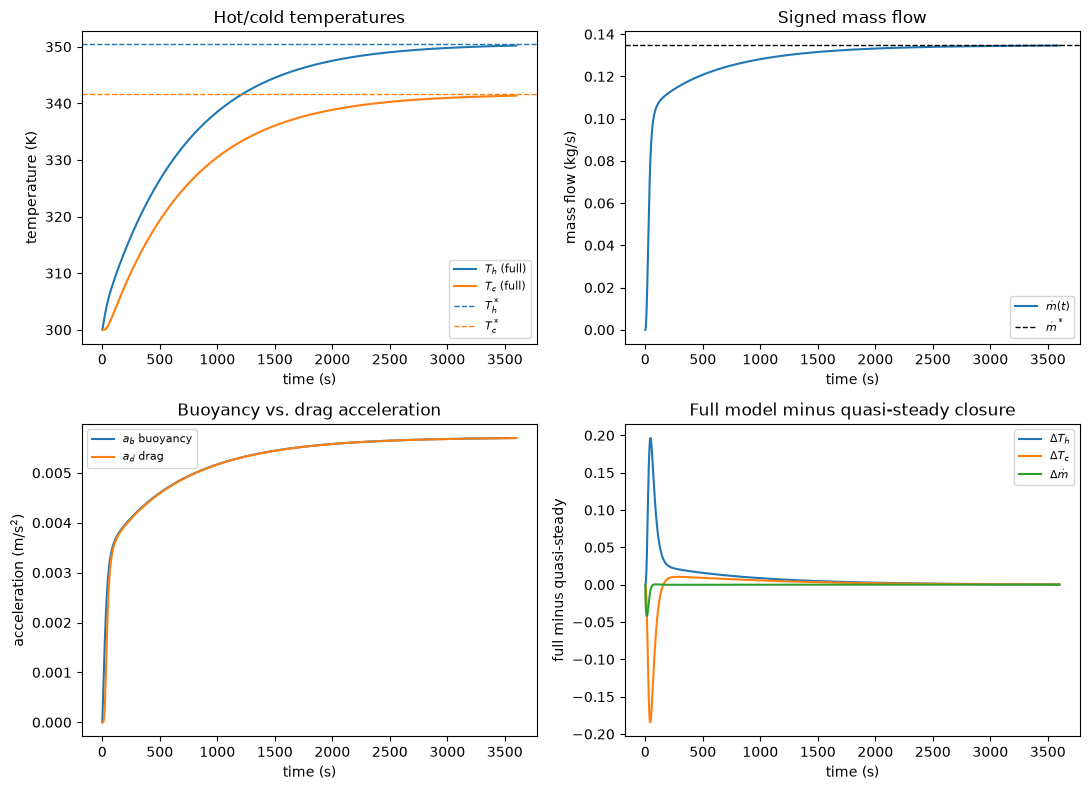

In [4]:
sol_full = solve_ivp(
    rhs_full, T_SPAN, Y0, method="Radau", t_eval=T_EVAL, args=(PARAMS,),
    rtol=1e-8, atol=[1e-10, 1e-8, 1e-8],
)
assert sol_full.success and sol_full.t.size == T_EVAL.size and np.all(np.isfinite(sol_full.y))

Y0_quasi = np.array([300.0, 300.0])
sol_quasi = solve_ivp(
    rhs_quasi, T_SPAN, Y0_quasi, method="Radau", t_eval=T_EVAL, args=(PARAMS,),
    rtol=1e-8, atol=[1e-8, 1e-8],
)
assert sol_quasi.success and sol_quasi.t.size == T_EVAL.size and np.all(np.isfinite(sol_quasi.y))

v_full, Th_full, Tc_full = sol_full.y
Th_quasi, Tc_quasi = sol_quasi.y
v_quasi = quasi_steady_velocity(Th_quasi - Tc_quasi, PARAMS)
mdot_full = PARAMS["rho"] * PARAMS["A"] * v_full
mdot_quasi = PARAMS["rho"] * PARAMS["A"] * v_quasi


def first_crossing_time(signal, target, times):
    """First time `signal` reaches `target`, linearly interpolated between samples."""
    reached = np.where(signal >= target)[0] if target >= signal[0] else np.where(signal <= target)[0]
    i = reached[0]
    if i == 0:
        return times[0]
    s0, s1 = signal[i - 1], signal[i]
    t0, t1 = times[i - 1], times[i]
    frac = (target - s0) / (s1 - s0)
    return t0 + frac * (t1 - t0)


# --- transient metrics (full model) ---
mdot_change = mdot_star - mdot_full[0]
t10 = first_crossing_time(mdot_full, mdot_full[0] + 0.10 * mdot_change, T_EVAL)
t90 = first_crossing_time(mdot_full, mdot_full[0] + 0.90 * mdot_change, T_EVAL)
rise_time = t90 - t10

overshoot_pct = 100.0 * max(0.0, Th_full.max() - Th_star) / (Th_star - PARAMS["T_sink"])


def settling_time(signal, steady_value, scale, times):
    within = np.abs(signal - steady_value) <= 0.01 * scale
    idx = np.where(~within)[0]
    last_bad = idx[-1] if idx.size else -1
    return times[last_bad + 1] if last_bad + 1 < times.size else times[-1]


t_settle_Th = settling_time(Th_full, Th_star, Th_star - PARAMS["T_sink"], T_EVAL)
t_settle_Tc = settling_time(Tc_full, Tc_star, Tc_star - PARAMS["T_sink"], T_EVAL)
t_settle_mdot = settling_time(mdot_full, mdot_star, mdot_star, T_EVAL)
reversal = bool(np.any(v_full[T_EVAL > 0] < 0))

print(f"10-90% mass-flow rise time: {rise_time:.1f} s")
print(f"Hot-leg overshoot: {overshoot_pct:.3f} %")
print(f"Settling times (1%): Th={t_settle_Th:.1f} s, Tc={t_settle_Tc:.1f} s, mdot={t_settle_mdot:.1f} s")
print(f"Flow reversal after startup: {reversal}")

# --- energy balance closure ---
Q_t = heat_input(T_EVAL, Q_BASE)
sink_t = ua_base(T_EVAL, PARAMS["UA"]) * (Tc_full - PARAMS["T_sink"])
net_external = Q_t - sink_t
integrated_net = np.trapezoid(net_external, T_EVAL)
integrated_Q = np.trapezoid(Q_t, T_EVAL)
stored_energy = Ch * (Th_full - PARAMS["T_sink"]) + Cc * (Tc_full - PARAMS["T_sink"])
delta_stored = stored_energy[-1] - stored_energy[0]
energy_imbalance = abs(integrated_net - delta_stored) / max(integrated_Q, 1.0)
print(f"Normalized energy-balance closure error: {energy_imbalance:.3e}")

# --- plots ---
fig, axes = plt.subplots(2, 2, figsize=(11, 8))

axes[0, 0].plot(T_EVAL, Th_full, label=r"$T_h$ (full)")
axes[0, 0].plot(T_EVAL, Tc_full, label=r"$T_c$ (full)")
axes[0, 0].axhline(Th_star, color="C0", ls="--", lw=1, label=r"$T_h^*$")
axes[0, 0].axhline(Tc_star, color="C1", ls="--", lw=1, label=r"$T_c^*$")
axes[0, 0].set_xlabel("time (s)")
axes[0, 0].set_ylabel("temperature (K)")
axes[0, 0].set_title("Hot/cold temperatures")
axes[0, 0].legend(fontsize=8)

axes[0, 1].plot(T_EVAL, mdot_full, label=r"$\dot m(t)$")
axes[0, 1].axhline(mdot_star, color="k", ls="--", lw=1, label=r"$\dot m^*$")
axes[0, 1].set_xlabel("time (s)")
axes[0, 1].set_ylabel("mass flow (kg/s)")
axes[0, 1].set_title("Signed mass flow")
axes[0, 1].legend(fontsize=8)

a_b = PARAMS["g"] * PARAMS["beta"] * PARAMS["H"] * (Th_full - Tc_full) / PARAMS["L"]
a_d = PARAMS["K"] * v_full * np.abs(v_full) / (2.0 * PARAMS["L"])
axes[1, 0].plot(T_EVAL, a_b, label=r"$a_b$ buoyancy")
axes[1, 0].plot(T_EVAL, a_d, label=r"$a_d$ drag")
axes[1, 0].set_xlabel("time (s)")
axes[1, 0].set_ylabel(r"acceleration (m/s$^2$)")
axes[1, 0].set_title("Buoyancy vs. drag acceleration")
axes[1, 0].legend(fontsize=8)

axes[1, 1].plot(T_EVAL, Th_full - Th_quasi, label=r"$\Delta T_h$")
axes[1, 1].plot(T_EVAL, Tc_full - Tc_quasi, label=r"$\Delta T_c$")
axes[1, 1].plot(T_EVAL, mdot_full - mdot_quasi, label=r"$\Delta \dot m$")
axes[1, 1].set_xlabel("time (s)")
axes[1, 1].set_ylabel("full minus quasi-steady")
axes[1, 1].set_title("Full model minus quasi-steady closure")
axes[1, 1].legend(fontsize=8)

fig.tight_layout()
plt.show()


## 5. Solution and diagnostic plots

Now change only the heater power, repeating the full transient for $Q\in\{1,2.5,5,10\}$ kW with all physical parameters, initial conditions, solver settings, and final time unchanged. For each case, tabulate the final simulated and analytical values of $\dot m$, $T_h$, and $T_c$. For each quantity, calculate relative steady-state error as $|x_{final}-x^*|/|x^*|$; for a temperature, compare temperature rise relative to the sink when measuring convergence so the Kelvin offset does not distort the percentage.

A power law $y\propto Q^n$ becomes a straight line $\log y = n\log Q + b$ on log-log axes, where the fitted slope is the exponent $n$. Fit ordinary straight lines to $(\log Q,\log \dot m^*)$ and $(\log Q,\log \Delta T^*)$ using the analytical steady values; compare the slopes with $1/3$ and $2/3$. Use final transient values only as an independent check that 3600 s is long enough to approach the equilibrium, not as the primary scaling data.

Plot analytical mass flow and hot-minus-cold temperature versus heat load on log-log axes. Include reference lines with the derived slopes, positioned to pass through one reference point, and label both axes with units. The cold-region balance gives $T_c-T_s=Q/UA$, which is linear in load because $UA$ is fixed. In contrast, the hot-to-cold difference is set by simultaneous heat transport and quadratic momentum loss, giving the two-thirds power.

   Q (W)  mdot* (kg/s)     mdot_f       err   Th* (K)      Th_f       err   Tc* (K)      Tc_f       err
  1000.0  7.883168e-02 7.870824e-02  1.57e-03   311.368   311.286  7.25e-03   308.333   308.260  8.77e-03
  2500.0  1.069910e-01 1.068437e-01  1.38e-03   326.423   326.245  6.76e-03   320.833   320.670  7.84e-03
  5000.0  1.348003e-01 1.346281e-01  1.28e-03   350.540   350.212  6.50e-03   341.667   341.360  7.35e-03
 10000.0  1.698377e-01 1.696335e-01  1.20e-03   397.419   396.804  6.31e-03   383.333   382.752  6.98e-03

Fitted exponent mdot* ~ Q^n: n = 0.33333 (expected 1/3 = 0.33333)
Fitted exponent dT*  ~ Q^n: n = 0.66667 (expected 2/3 = 0.66667)


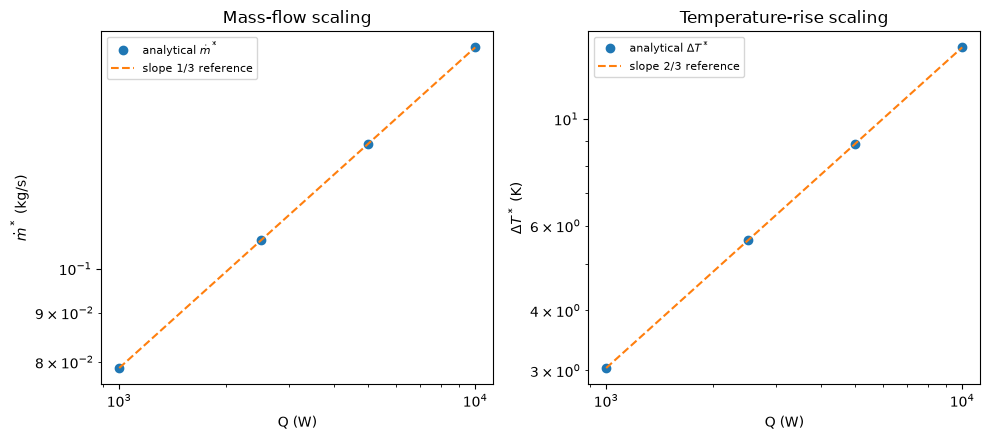

In [5]:
Q_LOADS = np.array([1.0, 2.5, 5.0, 10.0]) * 1000.0
sweep_rows = []
sweep_results = {}

for q in Q_LOADS:
    v_s, Th_s, Tc_s, mdot_s = analytical_steady(q, PARAMS)
    sol_q = solve_ivp(
        lambda t, y, p, q=q: rhs_full(t, y, p, qfun=lambda t, q=q: heat_input(t, q)),
        T_SPAN, Y0, method="Radau", t_eval=T_EVAL, args=(PARAMS,),
        rtol=1e-8, atol=[1e-10, 1e-8, 1e-8],
    )
    assert sol_q.success and sol_q.t.size == T_EVAL.size and np.all(np.isfinite(sol_q.y))
    v_f, Th_f, Tc_f = sol_q.y
    mdot_f = PARAMS["rho"] * PARAMS["A"] * v_f

    err_mdot = abs(mdot_f[-1] - mdot_s) / abs(mdot_s)
    err_Th = abs((Th_f[-1] - PARAMS["T_sink"]) - (Th_s - PARAMS["T_sink"])) / abs(Th_s - PARAMS["T_sink"])
    err_Tc = abs((Tc_f[-1] - PARAMS["T_sink"]) - (Tc_s - PARAMS["T_sink"])) / abs(Tc_s - PARAMS["T_sink"])

    sweep_rows.append({
        "Q_W": q, "mdot_final": mdot_f[-1], "mdot_star": mdot_s, "err_mdot": err_mdot,
        "Th_final": Th_f[-1], "Th_star": Th_s, "err_Th": err_Th,
        "Tc_final": Tc_f[-1], "Tc_star": Tc_s, "err_Tc": err_Tc,
    })
    sweep_results[q] = {"v_star": v_s, "Th_star": Th_s, "Tc_star": Tc_s, "mdot_star": mdot_s,
                         "Th_final": Th_f[-1], "Tc_final": Tc_f[-1], "mdot_final": mdot_f[-1]}

print(f"{'Q (W)':>8} {'mdot* (kg/s)':>13} {'mdot_f':>10} {'err':>9} "
      f"{'Th* (K)':>9} {'Th_f':>9} {'err':>9} {'Tc* (K)':>9} {'Tc_f':>9} {'err':>9}")
for r in sweep_rows:
    print(f"{r['Q_W']:>8.1f} {r['mdot_star']:>13.6e} {r['mdot_final']:>10.6e} {r['err_mdot']:>9.2e} "
          f"{r['Th_star']:>9.3f} {r['Th_final']:>9.3f} {r['err_Th']:>9.2e} "
          f"{r['Tc_star']:>9.3f} {r['Tc_final']:>9.3f} {r['err_Tc']:>9.2e}")

mdot_stars = np.array([sweep_results[q]["mdot_star"] for q in Q_LOADS])
dT_stars = np.array([sweep_results[q]["Th_star"] - sweep_results[q]["Tc_star"] for q in Q_LOADS])
log_q = np.log(Q_LOADS)

n_mdot, b_mdot = np.polyfit(log_q, np.log(mdot_stars), 1)
n_dT, b_dT = np.polyfit(log_q, np.log(dT_stars), 1)
print(f"\nFitted exponent mdot* ~ Q^n: n = {n_mdot:.5f} (expected 1/3 = {1/3:.5f})")
print(f"Fitted exponent dT*  ~ Q^n: n = {n_dT:.5f} (expected 2/3 = {2/3:.5f})")

fig, ax = plt.subplots(1, 2, figsize=(10, 4.5))
ax[0].loglog(Q_LOADS, mdot_stars, "o", label="analytical $\\dot m^*$")
ref_mdot = mdot_stars[0] * (Q_LOADS / Q_LOADS[0]) ** (1 / 3)
ax[0].loglog(Q_LOADS, ref_mdot, "--", label="slope 1/3 reference")
ax[0].set_xlabel("Q (W)")
ax[0].set_ylabel("$\\dot m^*$ (kg/s)")
ax[0].legend(fontsize=8)
ax[0].set_title("Mass-flow scaling")

ax[1].loglog(Q_LOADS, dT_stars, "o", label=r"analytical $\Delta T^*$")
ref_dT = dT_stars[0] * (Q_LOADS / Q_LOADS[0]) ** (2 / 3)
ax[1].loglog(Q_LOADS, ref_dT, "--", label="slope 2/3 reference")
ax[1].set_xlabel("Q (W)")
ax[1].set_ylabel(r"$\Delta T^*$ (K)")
ax[1].legend(fontsize=8)
ax[1].set_title("Temperature-rise scaling")

fig.tight_layout()
plt.show()


## 6. Automatic checks

Turn the model assumptions and numerical expectations into executable checks. A solver success flag alone is not enough: confirm the solver returned the complete requested time interval, every state is finite, and the physical parameters required in denominators or square roots are positive. The remaining checks distinguish model/algebra errors, integration errors, and loss of validity of the Boussinesq approximation. Assert:

- Every solve succeeds and returns finite states on the complete requested interval.
- Density, heat capacity, geometry, loss coefficient, conductance, and thermal masses are positive.
- Base-case final $v$, $T_h$, and $T_c$ are each within 1% of the analytical steady state (for temperatures, compare the rise above $T_s$ rather than the absolute Kelvin value).
- The maximum normalized integrated external energy imbalance is below $10^{-3}$.
- The analytical steady state makes each governing-equation residual negligible: heat-rate residuals below $10^{-9}\max(Q,1)$ and acceleration residual below $10^{-12}$ m/s2.
- The fitted analytical exponents differ from $1/3$ and $2/3$ by less than 0.03.
- The Boussinesq indicator $\beta\max|T_h-T_c|$ is reported and below 0.05 for every base/sweep case. This dimensionless product estimates the relative density change represented by the linear expansion model; larger values would make the constant-property approximation less credible.
- No temperature falls below 250 K or exceeds 450 K in this synthetic study.

Do not assert that the full model must overshoot, oscillate, or reverse; those are outcomes. Do not loosen tolerances to conceal a bookkeeping or sign error.

In [6]:
checks = []


def check(name, condition):
    checks.append((name, bool(condition)))


check("sol_full succeeded on full interval with finite states", sol_full.success and np.all(np.isfinite(sol_full.y)))
check("sol_quasi succeeded on full interval with finite states", sol_quasi.success and np.all(np.isfinite(sol_quasi.y)))

positive_params = ["rho", "cp", "A", "L", "H", "K", "M_h", "M_c", "UA"]
check("physical parameters are positive", all(PARAMS[k] > 0 for k in positive_params))

rel_v_err = abs(v_full[-1] - v_star) / abs(v_star)
rel_Th_err = abs((Th_full[-1] - PARAMS["T_sink"]) - (Th_star - PARAMS["T_sink"])) / abs(Th_star - PARAMS["T_sink"])
rel_Tc_err = abs((Tc_full[-1] - PARAMS["T_sink"]) - (Tc_star - PARAMS["T_sink"])) / abs(Tc_star - PARAMS["T_sink"])
check("base-case final v within 1% of analytical steady state", rel_v_err < 0.01)
check("base-case final Th within 1% of analytical steady state", rel_Th_err < 0.01)
check("base-case final Tc within 1% of analytical steady state", rel_Tc_err < 0.01)

check("normalized energy-balance closure error below 1e-3", energy_imbalance < 1e-3)

check("acceleration residual at analytical steady state below 1e-12 m/s2", abs(accel_residual) < 1e-12)
heat_rate_tol = 1e-9 * max(Q_BASE, 1.0)
check("dTh/dt residual below heat-rate tolerance", abs(dTh_residual * PARAMS["M_h"] * PARAMS["cp"]) < heat_rate_tol)
check("dTc/dt residual below heat-rate tolerance", abs(dTc_residual * PARAMS["M_c"] * PARAMS["cp"]) < heat_rate_tol)

check("fitted mdot* exponent within 0.03 of 1/3", abs(n_mdot - 1 / 3) < 0.03)
check("fitted dT* exponent within 0.03 of 2/3", abs(n_dT - 2 / 3) < 0.03)

boussinesq_base = PARAMS["beta"] * np.max(np.abs(Th_full - Tc_full))
boussinesq_sweep = [PARAMS["beta"] * abs(sweep_results[q]["Th_final"] - sweep_results[q]["Tc_final"]) for q in Q_LOADS]
boussinesq_max = max([boussinesq_base] + boussinesq_sweep)
print(f"Boussinesq indicator beta*max|Th-Tc| (worst case over base+sweep): {boussinesq_max:.4f}")
check("Boussinesq indicator below 0.05 for every base/sweep case", boussinesq_max < 0.05)

all_temps = np.concatenate([Th_full, Tc_full, Th_quasi, Tc_quasi] +
                            [np.array([sweep_results[q]["Th_final"], sweep_results[q]["Tc_final"]]) for q in Q_LOADS])
check("no temperature below 250 K or above 450 K", np.all((all_temps >= 250.0) & (all_temps <= 450.0)))

print()
n_pass = sum(1 for _, ok in checks if ok)
for name, ok in checks:
    print(f"[{'PASS' if ok else 'FAIL'}] {name}")
print(f"\n{n_pass}/{len(checks)} checks passed.")
assert n_pass == len(checks), "One or more verification checks failed."


Boussinesq indicator beta*max|Th-Tc| (worst case over base+sweep): 0.0030

[PASS] sol_full succeeded on full interval with finite states
[PASS] sol_quasi succeeded on full interval with finite states
[PASS] physical parameters are positive
[PASS] base-case final v within 1% of analytical steady state
[PASS] base-case final Th within 1% of analytical steady state
[PASS] base-case final Tc within 1% of analytical steady state
[PASS] normalized energy-balance closure error below 1e-3
[PASS] acceleration residual at analytical steady state below 1e-12 m/s2
[PASS] dTh/dt residual below heat-rate tolerance
[PASS] dTc/dt residual below heat-rate tolerance
[PASS] fitted mdot* exponent within 0.03 of 1/3
[PASS] fitted dT* exponent within 0.03 of 2/3
[PASS] Boussinesq indicator below 0.05 for every base/sweep case
[PASS] no temperature below 250 K or above 450 K

14/14 checks passed.


## 7. Discussion and next steps

Use the results to separate what follows directly from the equations from what is a transient outcome. At steady state, heat input must pass through the cold-side sink; during startup, some input instead raises the stored energy of the two control volumes. The momentum closure changes how quickly flow responds, while the steady balances make specific predictions independent of the integration method. In the discussion, connect each conclusion to a term or assumption in the model rather than treating the plots as self-explanatory.

Answer briefly:

1. Which feedback closes the loop between buoyancy and heat transport?
2. When is the quasi-steady momentum closure adequate, and what transient information does it remove?
3. Why does quadratic drag produce the $Q^{1/3}$ flow scaling in this closure?
4. Which assumptions would break first in a real decay-heat removal loop: constant properties, two thermal nodes, fixed $K$, single-phase flow, or instantaneous mixing?
5. What additional states and closure laws would a GOTHIC/TRACE-style system model need?

**Stretch goal (15-25 minutes):** At $t=1800$ s, reduce $UA$ from 120 to 40 W/K while holding $Q=5$ kW. Simulate the heat-sink-degradation transient, plot the new equilibrium approach, and verify the same global energy balance with time-dependent $UA(t)$. Before running, use the steady equations to predict the change: $T_c^*-T_s=Q/UA$ triples when $UA$ is divided by three, whereas $\Delta T^*$ and $v^*$ are unchanged by $UA$ in this model because their expressions depend on heat load and the momentum/transport parameters. Consequently, $T_h^*$ also rises by the increase in $T_c^*$. Confirm that the transient moves toward this new state rather than assuming it reaches equilibrium by 3600 s.

### References

- **Dedicated project reference:** International Atomic Energy Agency, *Natural Circulation in Water Cooled Nuclear Power Plants*, IAEA-TECDOC-1474, Vienna, 2005. [Open PDF](https://www-pub.iaea.org/MTCD/Publications/PDF/TE_1474_web.pdf). Focus on Section 4.2 and the single-phase hot-/cold-region balance model; compare its assumptions with today's three-state closure.
- **Solver reference:** [SciPy `solve_ivp` documentation](https://docs.scipy.org/doc/scipy/reference/generated/scipy.integrate.solve_ivp.html). Record SciPy version, method, tolerances, and solver status.
- **Paper to read:** Dean Wilson, Hector Iacovides, and Timothy J. Craft, "Numerical insights into the transient behaviour of single-phase Natural Circulation Loops for nuclear passive cooling applications," *Annals of Nuclear Energy*, 208, 110730, 2024. DOI: 10.1016/j.anucene.2024.110730. [Open-access article](https://doi.org/10.1016/j.anucene.2024.110730); [author manuscript](https://papers.ssrn.com/sol3/Delivery.cfm/49d50cad-eaf4-4b2a-8ef7-e4bee84683d5-MECA.pdf?abstractid=4646390&mirid=1). Read for how Rayleigh number, Prandtl number, aspect ratio, oscillation, and reversal emerge in 2D URANS beyond a lumped model.

### Topic ledger

| Date / record | Primary objective | Status |
|---|---|---|
| Older assignments, dates unavailable | Grid convergence and errors | User reported five repetitive assignments; individual records unavailable |
| 2026-10-05 | Grid convergence and discretization uncertainty | Inspected |
| 2026-10-06 corrected | Fixed-mesh advection, CFL, conservation, positivity, TV | Inspected |
| 2026-10-07 | Krylov methods and line-block preconditioning | Inspected |
| 2026-10-08 | Data layout, cache behavior, and kernel throughput | Inspected |
| 2026-10-09 | Nonlinear natural-circulation thermal-fluid modeling | This assignment |

Only four preceding distinct projects are recoverable, so a complete seven-project audit remains unavailable. The reported older repetitions remain excluded. This is assignment 3 of the ten-assignment exclusion established October 6; seven remain after today. Planned next primary objectives: optimization, multiphysics coupling, high-order reconstruction, then parallel algorithms. No grid-refinement, observed-order, Richardson, or GCI task appears here.